# Session 6 homework — scoreboard, `nn.Conv2d`, and an MLP on raw pixels

1. Put the MLP's validation and test macro-F1 on the scoreboard next to Session 5's forest.
2. Read the `nn.Conv2d` docs: which arguments are Session 4's kernel size, stride and padding?
3. Train the MLP on raw pixels (32×32×3 = 3,072 numbers): better or worse than 33 features, and why?

Everything uses this repo's lesion-level splits (`artifacts/splits`, seed 42) and the MLP recipe of the class notebook
(`src/milk10k/mlp.py`: Adam lr 1e-3, 50 epochs, batch 64, class-weighted cross-entropy, scaler fitted on train only).
The test split is scored **once per final model**; nothing is chosen on it.

In [1]:
# --- setup: find the repo root from wherever the notebook is opened -----------
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "milk10k").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import milk10k as mk
from milk10k import features as F

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

import torch, torch.nn as nn
from concurrent.futures import ThreadPoolExecutor
from sklearn.preprocessing import StandardScaler
from milk10k import filters as flt, mlp
from scipy import ndimage

IMG = mk.config.IMAGE_DIR
OUT = mk.config.ARTIFACT_DIR / "session06"
OUT.mkdir(parents=True, exist_ok=True)
base = json.loads((mk.config.ARTIFACT_DIR / "session05" / "baseline_scores.json").read_text())

frames = F.load_lesion_splits()                                     # one row per lesion; dermoscopic image = derm_id
ids = pd.concat([f["derm_id"] for f in frames.values()])
feats = F.feature_table(ids, cache=F.FEATURE_DIR / "features.npz")
y = {k: mlp.encode_labels(v["diagnosis_1"]) for k, v in frames.items()}
w = mlp.inverse_frequency_weights(y["train"])
print({k: len(v) for k, v in frames.items()}, "class weights", w.numpy().round(2))

def prepare(X):
    """train-only StandardScaler -> float32 tensors per split."""
    sc = StandardScaler().fit(X["train"])
    return {k: mlp.to_tensor(sc.transform(v)) for k, v in X.items()}, sc

def train_and_score(X, hidden=(64,), dropout=0.0, weight_decay=0.0, test=True, seed=0):
    m = mlp.make_mlp(X["train"].shape[1], hidden=hidden, dropout=dropout, seed=seed)
    hist = mlp.fit(m, X["train"], y["train"], X["val"], y["val"], class_weights=w, weight_decay=weight_decay, seed=seed)
    out = {"model": m, "hist": hist, "params": sum(p.numel() for p in m.parameters()),
           "val": mlp.scores(m, X["val"], y["val"])}
    if test:
        out["test"] = mlp.scores(m, X["test"], y["test"])
    return out

{'train': 3742, 'val': 749, 'test': 749} class weights [ 1.18 14.01  0.48]


## 1. The MLP on the 33 features, and the scoreboard

Same network as the class notebook: 33 → 64 → 3 (2,371 parameters). The features are Session 5's 33 (colour statistics, colour histogram, texture) of the dermoscopic image.

In [2]:
X33, _ = prepare({k: F.build_matrix("Session 5 set (33)", v, feats) for k, v in frames.items()})
r33 = train_and_score(X33)
print(f"MLP 33-64-3: {r33['params']:,} parameters   val macro-F1 {r33['val']['macro_f1']:.3f}   "
      f"test macro-F1 {r33['test']['macro_f1']:.3f}   test accuracy {r33['test']['accuracy']:.3f}")
cls = OUT / "mlp_scores.json"
if cls.exists():
    c = json.loads(cls.read_text())
    print(f"class notebook run: val {c['val_macro_f1']:.3f}   test {c['test_macro_f1']:.3f}   test accuracy {c['test_accuracy']:.3f}"
          "   (same recipe, a different mini-batch order)")

MLP 33-64-3: 2,371 parameters   val macro-F1 0.489   test macro-F1 0.480   test accuracy 0.637
class notebook run: val 0.489   test 0.480   test accuracy 0.633   (same recipe, a different mini-batch order)


## 3. MLP on raw pixels (done before the table so the scoreboard is complete)

Each dermoscopic photograph is shrunk to 32×32 (the 4:3 photo is squashed to a square) and flattened to 3,072 numbers,
scaled per pixel-channel with train-only statistics, then fed to the same network: 3,072 → 64 → 3. No hand-made feature: the
network has to find colour and texture structure from raw intensities by itself.

In [3]:
def load_pixels(isic_id):
    return F.load_rgb(IMG / f"{isic_id}.jpg", size=(32, 32)).astype(np.float32)        # (32, 32, 3)

t0 = time.perf_counter()
with ThreadPoolExecutor(8) as pool:
    raw = {k: np.stack(list(pool.map(load_pixels, v["derm_id"]))) for k, v in frames.items()}
print({k: v.shape for k, v in raw.items()}, f"{time.perf_counter() - t0:.0f} s")
Xraw, raw_scaler = prepare({k: v.reshape(len(v), -1) for k, v in raw.items()})        # 3,072 columns

rraw = train_and_score(Xraw)
rreg = train_and_score(Xraw, dropout=0.3, weight_decay=1e-3, test=False)              # one untuned regularised try (val only)
print(f"raw 3072-64-3:        {rraw['params']:,} parameters   val {rraw['val']['macro_f1']:.3f}   "
      f"test {rraw['test']['macro_f1']:.3f}   test accuracy {rraw['test']['accuracy']:.3f}")
print(f"raw + dropout/decay:  val {rreg['val']['macro_f1']:.3f}  (validation only)")

{'train': (3742, 32, 32, 3), 'val': (749, 32, 32, 3), 'test': (749, 32, 32, 3)} 9 s


raw 3072-64-3:        196,867 parameters   val 0.549   test 0.484   test accuracy 0.724
raw + dropout/decay:  val 0.522  (validation only)


In [4]:
# Is raw > features on validation more than seed noise? Five seeds each (validation only), plus per-class F1.
from sklearn.metrics import f1_score
five = {name: [train_and_score(X, test=False, seed=s) for s in range(5)]
        for name, X in [("33 features", X33), ("raw pixels", Xraw)]}
spread = pd.DataFrame({name: [r["val"]["macro_f1"] for r in rs] for name, rs in five.items()})
print("val macro-F1 over seeds 0-4:\n", spread.round(3).T.assign(mean=spread.mean(), std=spread.std(ddof=0)).round(3).to_string())

def per_class_f1(model, X):
    model.eval()
    with torch.no_grad():
        pred = model(X["val"]).argmax(1)
    return f1_score(y["val"], pred, average=None, labels=[0, 1, 2])
pc = pd.DataFrame({"33 features": per_class_f1(r33["model"], X33), "raw pixels": per_class_f1(rraw["model"], Xraw)}, index=F.CLASSES)
pc.round(3).assign(**{"val lesions": np.bincount(y["val"].numpy(), minlength=3)})

val macro-F1 over seeds 0-4:
                  0      1      2      3      4   mean    std
33 features  0.489  0.469  0.482  0.476  0.482  0.480  0.007
raw pixels   0.549  0.463  0.438  0.488  0.487  0.485  0.037


,33 features,raw pixels,val lesions
Benign,0.597,0.592,213
Indeterminate,0.131,0.256,17
Malignant,0.740,0.799,519


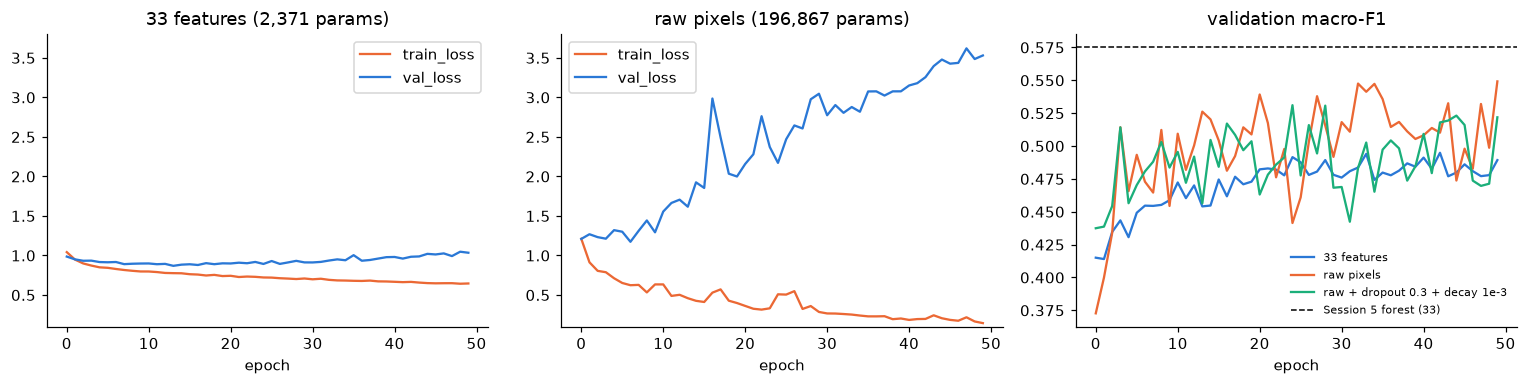

,33 features,raw pixels,raw + dropout/decay
parameters,2371,196867,196867
final train loss,0.646,0.144,0.541
final val loss,1.035,3.531,2.331
min val loss (epoch),0.869 @ 13,1.173 @ 6,1.110 @ 2
final val macro-F1,0.489,0.549,0.522


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, (name, r) in zip(axes[:2], [(f"33 features ({r33['params']:,} params)", r33), (f"raw pixels ({rraw['params']:,} params)", rraw)]):
    r["hist"][["train_loss", "val_loss"]].plot(ax=ax, color=[mk.ORANGE, mk.BLUE], title=name)
    ax.set_xlabel("epoch"); ax.set_ylim(0.1, 3.8)
axes[2].plot(r33["hist"].val_f1, color=mk.BLUE, label="33 features")
axes[2].plot(rraw["hist"].val_f1, color=mk.ORANGE, label="raw pixels")
axes[2].plot(rreg["hist"].val_f1, color=mk.AQUA, label="raw + dropout 0.3 + decay 1e-3")
axes[2].axhline(base["forest_33"]["val_macro_f1"], color="k", ls="--", lw=1, label="Session 5 forest (33)")
axes[2].set_title("validation macro-F1"); axes[2].set_xlabel("epoch"); axes[2].legend(fontsize=7.5, frameon=False)
plt.tight_layout(); plt.show()
pd.DataFrame({name: {"parameters": r["params"], "final train loss": round(r["hist"].train_loss.iloc[-1], 3), "final val loss": round(r["hist"].val_loss.iloc[-1], 3),
                     "min val loss (epoch)": f"{r['hist'].val_loss.min():.3f} @ {int(r['hist'].val_loss.idxmin())}",
                     "final val macro-F1": round(r["hist"].val_f1.iloc[-1], 3)}
              for name, r in [("33 features", r33), ("raw pixels", rraw), ("raw + dropout/decay", rreg)]})

**Why? A test of the "no spatial prior" argument.** A fully-connected layer treats pixel (5, 7) and pixel (5, 8) as unrelated inputs and
learns a separate weight for every position. A lesion shifted a few pixels is, to it, an entirely new input. The 33 hand-made features
(colour statistics, histograms) do not depend on where things are. To check this, every validation image is rolled sideways by
12.5 % of its width (the content wraps around) and both models are scored again, without retraining.

In [6]:
def val_inputs(shift_frac):
    """Validation images rolled sideways, then turned into (33 features, raw 32x32 pixels) exactly as in training."""
    f33, px = [], []
    for i in frames["val"]["derm_id"]:
        rgb = F.load_rgb(IMG / f"{i}.jpg")                                           # 200 x 150
        rgb = np.roll(rgb, int(shift_frac * rgb.shape[1]), axis=1)
        f33.append(np.concatenate([F.color_stats(rgb), F.color_histogram(rgb), F.texture_features(rgb)]))
        small = np.asarray(__import__("PIL.Image", fromlist=["Image"]).fromarray(rgb.astype(np.uint8)).resize((32, 32)), dtype=np.float32)
        px.append(small.ravel())
    return np.stack(f33), np.stack(px)

sc33 = StandardScaler().fit(F.build_matrix("Session 5 set (33)", frames["train"], feats))
inputs = {frac: val_inputs(frac) for frac in (0.0, 0.125)}
rows = []
for name, scaler, col in [("33 features", sc33, 0), ("raw pixels", raw_scaler, 1)]:
    for frac, arrays in inputs.items():
        X = mlp.to_tensor(scaler.transform(arrays[col]))
        f1 = [mlp.scores(r["model"], X, y["val"])["macro_f1"] for r in five[name]]
        rows.append({"model": name, "shift": f"{frac:.1%} of width", "val macro-F1 (mean of 5 seeds)": np.mean(f1), "std": np.std(f1)})
shift = pd.DataFrame(rows).set_index(["model", "shift"])
shift.round(3)

val macro-F1 (mean of 5 seeds)    std
model       shift                                                
33 features 0.0% of width                            0.480  0.007
            12.5% of width                           0.481  0.009
raw pixels  0.0% of width                            0.486  0.036
            12.5% of width                           0.470  0.047

## 1b. Scoreboard

Validation and test macro-F1 of everything so far, on the same splits. "Session 5 forest (33)" is the like-for-like row (same 33 inputs
as the MLP); "Session 5 best" is the winner of the Session 5 grid, which also sees the clinical photograph.

In [7]:
def row(name, val, test, params, acc=None):
    return {"model": name, "parameters": params, "val macro-F1": val, "test macro-F1": test, "test accuracy": acc}
board = pd.DataFrame([
    row("majority class",                                  base["majority"]["val_macro_f1"], base["majority"]["test_macro_f1"], 0, 0.694),
    row("Session 5 forest, 33 features",                   base["forest_33"]["val_macro_f1"], base["forest_33"]["test_macro_f1"], None),
    row("Session 5 best: forest, derm + clinical (66)",    base["val_macro_f1"], base["test_macro_f1"], None, base["test_accuracy"]),
    row("Session 6 MLP 33-64-3 (33 features)",             r33["val"]["macro_f1"], r33["test"]["macro_f1"], r33["params"], r33["test"]["accuracy"]),
    row("Session 6 MLP 3072-64-3 (raw 32x32x3 pixels)",    rraw["val"]["macro_f1"], rraw["test"]["macro_f1"], rraw["params"], rraw["test"]["accuracy"]),
]).set_index("model")
board.round(3).to_csv(OUT / "scoreboard.csv")
(OUT / "homework_scores.json").write_text(json.dumps({
    "mlp_33": {"val_macro_f1": round(r33["val"]["macro_f1"], 3), "test_macro_f1": round(r33["test"]["macro_f1"], 3)},
    "mlp_raw_pixels": {"val_macro_f1": round(rraw["val"]["macro_f1"], 3), "test_macro_f1": round(rraw["test"]["macro_f1"], 3)},
    "mlp_raw_regularised_val_only": round(rreg["val"]["macro_f1"], 3)}, indent=2))
board.round(3)

,parameters,val macro-F1,test macro-F1,test accuracy
model,,,,
majority class,0.0,0.273,0.273,0.694
"Session 5 forest, 33 features",NaN,0.575,0.528,NaN
"Session 5 best: forest, derm + clinical (66)",NaN,0.568,0.536,0.744
Session 6 MLP 33-64-3 (33 features),2371.0,0.489,0.480,0.637
Session 6 MLP 3072-64-3 (raw 32x32x3 pixels),196867.0,0.549,0.484,0.724


## 2. `nn.Conv2d`: which arguments are Session 4's kernel size, stride and padding?

In [8]:
import inspect
print("nn.Conv2d" + str(inspect.signature(nn.Conv2d.__init__)).replace("(self, ", "("))

nn.Conv2d(in_channels: int, out_channels: int, kernel_size: Union[int, tuple[int, int]], stride: Union[int, tuple[int, int]] = 1, padding: Union[str, int, tuple[int, int]] = 0, dilation: Union[int, tuple[int, int]] = 1, groups: int = 1, bias: bool = True, padding_mode: Literal['zeros', 'reflect', 'replicate', 'circular'] = 'zeros', device=None, dtype=None) -> None


| Session 4 idea | `nn.Conv2d` argument | meaning |
|---|---|---|
| **kernel size** (3×3 Sobel, 7×7 Gabor…) | `kernel_size` | height × width of the window the filter slides over (an int `3` or a pair `(3, 3)`) |
| **stride** (how far the window moves) | `stride` (default 1) | step in pixels between two positions; stride 2 halves the output |
| **padding** (border handling; the `mode=` of `ndimage`) | `padding` (default 0), `padding_mode` | rows/columns added around the image so the window fits at the border; `padding_mode="zeros"`/`"reflect"`/`"replicate"` ≈ filling with 0 / `reflect` / `nearest` |
| **the kernel values** (the Sobel numbers) | `weight`, shape `(out_channels, in_channels, kH, kW)` | *learned* instead of hand-written |
| number of filters in the bank | `out_channels` | one output map per filter |
| grayscale vs RGB input | `in_channels` | 1 or 3; each filter has one 2-D kernel per input channel, summed |

Two more arguments exist but were not part of Session 4: `dilation` (spacing between kernel taps) and `groups`. Output size per axis:
`⌊(H + 2·padding − kernel_size) / stride⌋ + 1`. `Conv2d` computes cross-correlation (the kernel is *not* flipped), like `ndimage.correlate` and the Session 4 code.

In [9]:
# 1) A Conv2d holding the Sobel kernel IS Session 4's Sobel filter.
gray = F.load_rgb(IMG / f"{frames['val']['derm_id'].iloc[0]}.jpg").mean(axis=2)                # 150 x 200
x = torch.tensor(gray, dtype=torch.float32)[None, None]                                         # (batch, channels, H, W)
conv = nn.Conv2d(1, 1, kernel_size=3, stride=1, padding=1, padding_mode="replicate", bias=False)
with torch.no_grad():
    conv.weight[:] = torch.tensor(flt.SOBEL_X, dtype=torch.float32)                             # kernel size 3x3, values = Sobel
    out = conv(x)[0, 0].numpy()
print("Conv2d(Sobel) vs ndimage.sobel, max |difference|:", np.abs(out - ndimage.sobel(gray, axis=1, mode="nearest")).max())

# 2) The output-size formula, checked.
rows = []
for k, s, p in [(3, 1, 0), (3, 1, 1), (3, 2, 1), (7, 2, 3), (5, 1, 2)]:
    o = nn.Conv2d(1, 1, kernel_size=k, stride=s, padding=p)(x).shape[-2:]
    rows.append({"kernel_size": k, "stride": s, "padding": p, "output (H, W)": tuple(o),
                 "formula (H, W)": ((150 + 2 * p - k) // s + 1, (200 + 2 * p - k) // s + 1)})
display(pd.DataFrame(rows))

# 3) Session 4's learned filters were exactly this layer: ResNet-18 conv1.
c1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
print("ResNet-18 conv1:", tuple(c1.weight.shape), f"{c1.weight.numel():,} weights; 224x224x3 in ->", tuple(c1(torch.zeros(1, 3, 224, 224)).shape[1:]), "out")
print(f"same image size through nn.Linear(3*224*224, 64): {3 * 224 * 224 * 64:,} weights - convolution shares one small kernel across all positions")

Conv2d(Sobel) vs ndimage.sobel, max |difference|: 9.155273443184342e-05


,kernel_size,stride,padding,"output (H, W)","formula (H, W)"
0,3,1,0,"(148, 198)","(148, 198)"
1,3,1,1,"(150, 200)","(150, 200)"
2,3,2,1,"(75, 100)","(75, 100)"
3,7,2,3,"(75, 100)","(75, 100)"
4,5,1,2,"(150, 200)","(150, 200)"


ResNet-18 conv1: (64, 3, 7, 7) 9,408 weights; 224x224x3 in -> (64, 112, 112) out
same image size through nn.Linear(3*224*224, 64): 9,633,792 weights - convolution shares one small kernel across all positions


## Answers

**1. Scoreboard** (above): the MLP on the 33 features scores **0.489 validation / 0.480 test** macro-F1, against **0.575 / 0.528** for the Session 5 forest on the same inputs (and 0.568 / 0.536 for the Session 5 winner, which also sees the clinical photograph; majority class 0.273). The MLP is 0.09 behind on validation, far beyond its seed noise (± 0.008); on test the 0.05 gap is inside the forest's bootstrap interval ([0.452, 0.597] in Session 5).

**2. `nn.Conv2d`:** `kernel_size` is Session 4's kernel size, `stride` is the step the window moves between positions, `padding` is the border handling (`padding_mode` chooses what fills it). The kernel *values*, the Sobel numbers, become the learned `weight` tensor, and `out_channels` is the number of filters in the bank. A `Conv2d` loaded with the Sobel kernel reproduces `ndimage.sobel` to float precision (difference 9e-5).

**3. Raw pixels (32 × 32 × 3 = 3,072 inputs): not better, roughly equal in macro-F1 and worse in every other way.**

| | 33 features | raw pixels |
|---|---|---|
| parameters | 2,371 | 196,867 |
| test macro-F1 (seed 0) | 0.480 | 0.484 |
| validation macro-F1, mean ± std over seeds 0-4 | 0.480 ± 0.007 | 0.485 ± 0.037 |
| final train / validation loss | 0.65 / 1.03 | 0.14 / 3.53 |

- The raw-pixel network's headline validation score (0.549) is the best of its five seeds; the average (0.485) is the same as the features'. Its higher test accuracy (0.724 against 0.637) does not carry over to macro-F1, which is a tie on test.
- **Why it does not win.** (a) *Overfitting.* 196,867 weights for 3,742 lesions: training loss falls to 0.14 while validation loss is lowest at epoch 6 (1.17) and ends at 3.53. Dropout 0.3 plus weight decay brings the final validation loss to 2.33 and F1 to 0.522 (one untuned try, validation only): better behaved, no better in F1. (b) *No notion of position or neighbourhood.* Every pixel is an unrelated input, so the network can only use per-pixel colour and brightness, the information the colour statistics already summarise; the texture and edge measures need neighbouring pixels, and 32 × 32 has blurred most of that away. (c) *Variance.* Five times larger across seeds than for the features.
- **Translation check.** Rolling each validation image by 12.5 % of its width costs the raw-pixel network 0.486 → 0.470 and the features nothing (0.480 → 0.481). The direction matches the argument that a fully-connected layer has no translation prior, but the drop is smaller than the seed spread (0.04), so this is weak evidence, not a proof.
- **What the 33 features have that raw pixels lack:** they are translation-invariant summaries, designed by a person, fewer than the number of training examples.  To get the benefit of raw pixels without the cost you need layers that share weights across positions: convolutions. `Conv2d(3, 64, 7)` has 9,408 weights, a `Linear` layer from a 224 × 224 × 3 image to 64 units has 9.6 million.
- Caveat: one split, 17 validation Indeterminate lesions (per-class F1 for that class is 0.26 raw vs 0.13 features, a difference of one or two lesions), so differences of a few hundredths in macro-F1 are not reliable.